<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Introduction to Logistic Regression

_Authors:_ Tim Book

---

### Learning Objectives
- Distinguish between regression and classification problems.
- Fit, generate predictions from, and evaluate a logistic regression model in `sklearn`.
- Understand how to interpret the coefficients of logistic regression.
- Know the benefits of logistic regression as a classifier.

In [1]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

## Graduate School Admissions

---

Today, we'll be applying logistic regression to solve the following problem: "Given one's GPA, will a student be admitted to a specific graduate program?"

In [4]:
# Read in the data.
admissions = pd.read_csv('data/grad_admissions.csv')
admissions.head()

,admit,gre,gpa
0,0,380.0,2.915018
1,1,660.0,4.044540
2,1,800.0,4.950714
3,1,640.0,3.921994
4,0,520.0,2.069878


The columns are:
- `admit`: A binary 0/1 variable indicating whether or not a student was admitted, where 1 means admitted and 0 means not admitted.
- `gre`: The student's [GRE (Graduate Record Exam)](https://en.wikipedia.org/wiki/Graduate_Record_Examinations) score.
- `gpa`: The student's GPA.

In [5]:
# How many missing values do we have in each column?
admissions.isnull().sum()

admit     0
gre      20
gpa      20
dtype: int64

In [9]:
# What do the missing value rows look like?
admissions[admissions.gre.isna()]

,admit,gre,gpa
187,0,NaN,NaN
212,0,NaN,2.362765
587,0,NaN,NaN
612,0,NaN,2.502466
987,0,NaN,NaN
1012,0,NaN,2.507765
1387,0,NaN,NaN
1412,0,NaN,2.075422
1787,0,NaN,NaN
1812,0,NaN,2.359568


In [10]:
admissions[admissions.gpa.isna()]

,admit,gre,gpa
187,0,NaN,NaN
236,1,660.0,NaN
587,0,NaN,NaN
636,1,660.0,NaN
987,0,NaN,NaN
1036,1,660.0,NaN
1387,0,NaN,NaN
1436,1,660.0,NaN
1787,0,NaN,NaN
1836,1,660.0,NaN


In [11]:
# Drop every row that has an NA... but also, is this a good idea? 
# (Discuss)
admissions.dropna(inplace=True)

## EDA: Can we predict admission from GPA? (or GRE?)

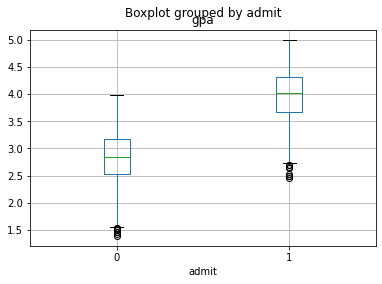

In [13]:
admissions.boxplot(column='gpa', by='admit');

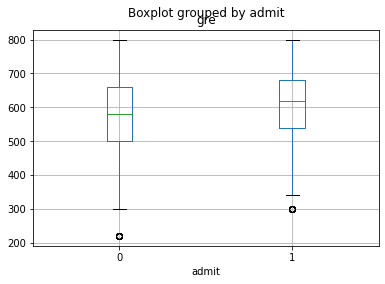

In [15]:
admissions.boxplot(column='gre', by='admit');

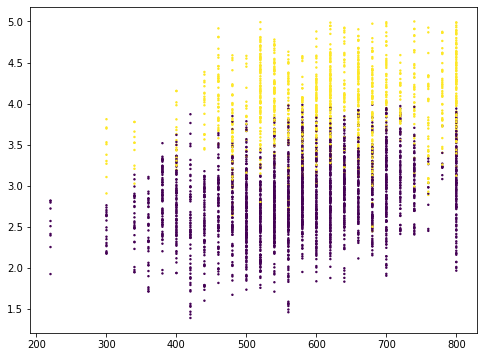

In [19]:
plt.figure(figsize=(8, 6))
plt.scatter(admissions.gre, admissions.gpa, c=admissions.admit, s=2);

# Let's Do It: Fit a Logistic Regression Model!
We can follow the same steps to build a logistic regression model that we follow to build a linear regression model.

1. Define X & y
2. Instantiate the model.
3. Fit the model.
4. Generate predictions.
5. Evaluate model.

In [21]:
# Step 1: Split into training & testing sets
X = admissions[['gpa']]
y = admissions['admit']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 2022)

In [22]:
X_train.shape

(2977, 1)

In [23]:
X_test.shape

(993, 1)

In [24]:
# Step 2: Instantiate our model.
logreg = LogisticRegression(penalty='none')

# Step 3: Fit our model.
logreg.fit(X_train, y_train)

print(f'Logistic Regression Intercept: {logreg.intercept_}')
print(f'Logistic Regression Coefficient: {logreg.coef_}')

Logistic Regression Intercept: [-18.59364106]
Logistic Regression Coefficient: [[5.19476598]]


#### Interpretations!
Are our model results surprising? Do they make sense? Let's interpret our slope to see.

In [27]:
np.exp(5.19*0.1)

1.6803464627827445

For a 0.1 increase in GPA, we'd expect our probability of being admitted to increase by a factor of 68%!

There are two methods in `sklearn` to be aware of when using logistic regression:
- `.predict()`
- `.predict_proba()`

In [15]:
# Step 4 (part 1): Generate predicted values.
logreg.predict(X_test)[:10]

array([0, 0, 0, 1, 0, 0, 0, 1, 1, 0])

In [16]:
# Step 4 (part 2): Generate predicted probabilities.
np.round(logreg.predict_proba(X_test), 3)

array([[0.895, 0.105],
       [0.82 , 0.18 ],
       [0.995, 0.005],
       ...,
       [0.58 , 0.42 ],
       [0.993, 0.007],
       [0.98 , 0.02 ]])

<details><summary>How would you interpret the predict_proba() output?</summary>
    
- This shows the probability of being rejected ($P(Y=0)$) and the probability of being admitted ($P(Y=1)$) for each observation in the testing dataset.
- The first array, corresponds to the first testing observation.
    - The `.predict()` value for this observation is 0. This is because $P(Y=0) > P(Y=1)$.
- The second array, corresponds to the second testing observation.
    - The `.predict()` value for this observation is 0. This is because $P(Y=0) > P(Y=1)$.
</details>

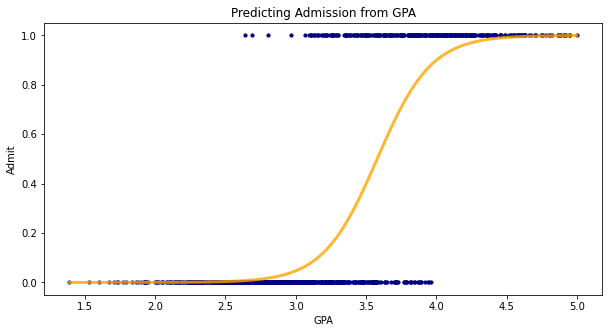

In [28]:
# Visualizing logistic regression probabilities.

plt.figure(figsize=(10, 5))

plt.scatter(X_test, y_test, s=10, c='navy');

plt.plot(
    X_test.sort_values('gpa'),
    logreg.predict_proba(X_test.sort_values('gpa'))[:,1],
    color='orange',
    alpha=0.8,
    lw=3
)

plt.xlabel('GPA')
plt.ylabel('Admit')
plt.title('Predicting Admission from GPA');

In [29]:
# Step 5: Evaluate model.
logreg.score(X_train, y_train)

0.9005710446758481

In [30]:
logreg.score(X_test, y_test)

0.8862034239677744

By default, the `.score()` method for classification models gives us the accuracy score.

$$
\begin{eqnarray*}
\text{Accuracy} = \frac{\text{number of correct predictions}}{\text{number of total predictions}}
\end{eqnarray*}
$$

<details><summary>Remind me: what does .score() tell me for a regression model?</summary>
    
- The $R^2$ score.
- Remember that $R^2$ is the proportion of variance in our $Y$ values that are explained by our model.
</details>

## Other Classification Metrics
Yes, of course there are many more! We'll soon see that **accuracy is actually often a pretty bad error metric!** More on this later.

## Multiclass Classification?
Logistic regression is **only** for binary classification problems! However, there are two "hacks" that allow us to fit multiclass classification problems using the same/similar methodology. They are:

#### Multinomial logistic regression
Normally, logistic regression is based off of the _Bernoulli distribution_, since our y-variable can be represented with a Bernoulli trial. We can instead base our y-variable off the _multinomial distribution_ and fit a model that way. It's more theoretically "pure" than OVR below, but less commonly used.

#### One-vs-Rest (OVR) logistic regression
A more common alternative is the _one-versus-rest_ technique. It works like this:

1. For category $k$, set $y = 1$ when the response is $k$ and $y = 0$ otherwise
1. Fit a logistic regression with this new $y$, and record the $\hat y$ for each observation
1. Repeat steps 1 and 2 for each category in our response variable
1. The true prediction is the $\hat y$ with the highest probability after all models are fit

You can select between these techniques with the following argument:

```python
LogisticRegression(multi_class='multinomial')
```

or

```python
LogisticRegression(multi_class='ovr')
```

## Conclusion

The goal of logistic regression is to find the best-fitting model to describe the relationship between a binary outcome and a set of independent variables.

Logistic regression generates the coefficients of a formula to predict a logit transformation of the probability that the characteristic of interest is present.

## Interview Questions

<details><summary>What is the difference between a classification and a regression problem?</summary>
    
- A classification problem has a categorical $Y$ variable. A regression problem has a numeric $Y$ variable.
</details>

<details><summary>What are some of the benefits of logistic regression as a classifier?</summary>

(Answers may vary; this is not an exhaustive list!)
- Logistic regression is a classification algorithm that shares similar properties to linear regression.
- The coefficients in a logistic regression model are interpretable. (They represent the change in log-odds caused by the input variables.)
- Logistic regression is a very fast model to fit and generate predictions from.
- It is by far the most common classification algorithm.

**Note**: The original interview question was "If you're comparing decision trees and logistic regression, what are the pros and cons of each?"
</details>